## Configurar o uso da GPU (Nvidia e AMD)

In [1]:
import torch
from ultralytics import YOLO

def definir_dispositivo_teste():
    """
    Detecta o hardware disponível para acelerar os testes (inferência).
    Retorna o dispositivo e um booleano indicando se é AMD (DirectML).
    """
    # 1. Verifica se há GPU NVIDIA (CUDA)
    if torch.cuda.is_available():
        print("🚀 GPU NVIDIA Detectada! Testes rodarão via CUDA.")
        return "cuda:0", False

    # 2. Verifica se há GPU AMD/Intel (DirectML no Windows)
    try:
        import torch_directml
        # Força uma inicialização de teste para garantir que o DirectML está conversando com placas AMD
        dml_device = torch_directml.device()
        print(f"🚀 GPU AMD/Intel Detectada! Testes rodarão via DirectML ({dml_device}).")
        return dml_device, True
    except Exception as e:
        print(f"⚠️ Nota sobre AMD: DirectML não inicializado ou indisponível. Motivo: {e}")

    # 3. Fallback para CPU
    print("💻 Nenhuma GPU detectada ou configurada. Os testes rodarão no CPU.")
    return "cpu", False

# Define as variáveis globais de hardware
DISPOSITIVO_TESTE, EH_AMD = definir_dispositivo_teste()


🚀 GPU AMD/Intel Detectada! Testes rodarão via DirectML (privateuseone:0).


## Carregando o modelo e preparando os caminhos dos arquivos

In [2]:
import os
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import onnxruntime as ort
import onnx

# 1. Defina o dataset que será validado neste momento (Ex: 'placas', 'ingredientes')
DATASET_ATIVO = "placas" 
ARQUIVO_CONFIG = f"../data_{DATASET_ATIVO}.yaml"

# 2. Carrega o modelo (Aponte para o modelo padrão ou para o seu customizado após o treino)

# MODELO_PATH = "../models/yolov8s.pt" # Baseline padrão
MODELO_PATH = "../models/yolov8s.onnx" # Formato .onnx
# MODELO_PATH = f"../models/treinamentos/yolo_{DATASET_ATIVO}/weights/best.pt"

print(f"Carregando o modelo: {MODELO_PATH}")

# === CORREÇÃO AUTOMÁTICA DE VERSÃO ONNX ===
try:
    model_proto = onnx.load(MODELO_PATH)
    # Se o arquivo for IR 14, faz o downgrade automático para garantir compatibilidade universal
    if model_proto.ir_version > 13:
        print(f"🔄 Detectada versão IR {model_proto.ir_version}. Convertendo automaticamente para IR 13 para compatibilidade...")
        model_proto.ir_version = 13
        onnx.save(model_proto, MODELO_PATH)
        print("✅ Arquivo ONNX atualizado com sucesso!")
except Exception as e:
    print(f"Nota: Não foi necessário ajustar os metadados do ONNX. Razão: {e}")
# ============================================================================

# Criamos uma variável global para guardar o dicionário de classes dinâmico
NOMES_CLASSES_DINAMICO = {}

if EH_AMD:
    print("Configurando ambiente ONNX Runtime puro para GPU AMD...")
    ort_session = ort.InferenceSession(MODELO_PATH, providers=['CPUExecutionProvider'])
    
    # Extrai dinamicamente o dicionário de classes embutido dentro dos metadados do arquivo ONNX
    meta = ort_session.get_modelmeta().custom_metadata_map
    if 'names' in meta:
        NOMES_CLASSES_DINAMICO = eval(meta['names'])
    else:
        print("⚠️ Aviso: Não foi possível ler as classes dos metadados do ONNX automaticamente.")
        
    print(f"Modelo ONNX mapeado com sucesso para a arquitetura AMD!")
else:
    model = YOLO(MODELO_PATH)
    model.to(DISPOSITIVO_TESTE)
    NOMES_CLASSES_DINAMICO = model.names
    print(f"Modelo carregado com sucesso no dispositivo: {DISPOSITIVO_TESTE}")

print(f"✨ Mapeamento de classes detectado dinamicamente: {list(NOMES_CLASSES_DINAMICO.values())[:5]}... ({len(NOMES_CLASSES_DINAMICO)} classes total).")

Carregando o modelo: ../models/yolov8s.onnx
🔄 Detectada versão IR 14. Convertendo automaticamente para IR 13 para compatibilidade...
✅ Arquivo ONNX atualizado com sucesso!
Configurando ambiente ONNX Runtime puro para GPU AMD...
Modelo ONNX mapeado com sucesso para a arquitetura AMD!
✨ Mapeamento de classes detectado dinamicamente: ['person', 'bicycle', 'car', 'motorcycle', 'airplane']... (80 classes total).


## TESTE 1 – Inferência em uma única Imagem Individual

--- Iniciando Inferência para Dataset: 'placas' ---

--- DETECÇÕES ESTRUTURADAS (SAÍDA DINÂMICA DA API) ---
Nenhum objeto detectado acima do limiar de 0.40.

--- VISUALIZAÇÃO GRÁFICA ---


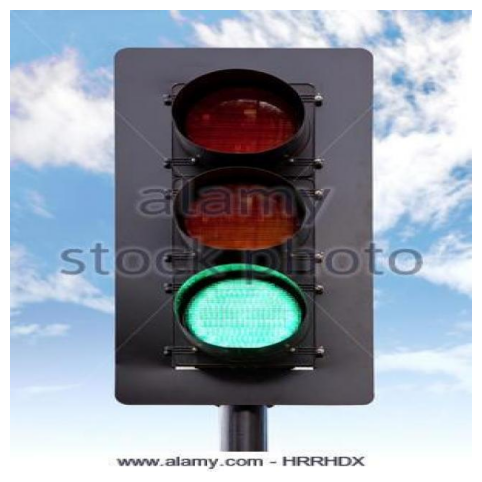

In [3]:
import numpy as np

# Defina o caminho de uma imagem de teste avulsa
IMAGEM_TESTE = "../tests/placas/lampu-hijau--95-_jpg.rf.16fb6212da51e975031103a45d1e65d7.jpg"

print(f"--- Iniciando Inferência para Dataset: '{DATASET_ATIVO}' ---")

# Criamos uma lista unificada para guardar as detecções independente de qual motor rodar
caixas_detectadas_geral = []

# Carrega a imagem original com OpenCV para desenho e plotagem gráfica
img_bgr = cv2.imread(IMAGEM_TESTE)
h_orig, w_orig = img_bgr.shape[:2]

if EH_AMD:
    # --- FLUXO DE EXECUÇÃO EXCLUSIVO AMD (SEM ERROS DE INFERENCE_MODE) ---
    img_resized = cv2.resize(img_bgr, (640, 640))
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Transpõe para o formato BCHW esperado pelo YOLO (1, 3, 640, 640) e normaliza
    input_data = np.expand_dims(img_rgb.transpose(2, 0, 1), axis=0).astype(np.float32) / 255.0
    
    input_name = ort_session.get_inputs()[0].name
    outputs = ort_session.run(None, {input_name: input_data})
    predictions = np.squeeze(outputs[0]).T  # Ajuste para extrair a matriz correta do YOLOv8
    
    for pred in predictions:
        x_center, y_center, width, height = pred[:4]
        scores = pred[4:]
        cls_id = int(np.argmax(scores))
        conf = float(scores[cls_id])
        
        if conf > 0.4:  # Filtro de confiança mínima
            # Converte formato YOLO (centro, largura, altura) para pixels reais da imagem original
            x_min = int((x_center - width / 2) * (w_orig / 640.0))
            y_min = int((y_center - height / 2) * (h_orig / 640.0))
            x_max = int((x_center + width / 2) * (w_orig / 640.0))
            y_max = int((y_center + height / 2) * (h_orig / 640.0))
            
            caixas_detectadas_geral.append((x_min, y_min, x_max, y_max, conf, cls_id))
else:
    # --- FLUXO DE EXECUÇÃO PADRÃO (NVIDIA CUDA / CPU UNIFICADO) ---
    with torch.inference_mode():
        resultados = model(IMAGEM_TESTE, imgsz=640, conf=0.25, device=DISPOSITIVO_TESTE)
        
    for result in resultados:
        for box in result.boxes:
            conf = float(box.conf)
            if conf > 0.4:
                cls_id = int(box.cls)
                x_min, y_min, x_max, y_max = box.xyxy.tolist()[0]
                caixas_detectadas_geral.append((int(x_min), int(y_min), int(x_max), int(y_max), conf, cls_id))


# --- PÓS-PROCESSAMENTO VISUAL E ESTRUTURADO UNIFICADO ---
print("\n--- DETECÇÕES ESTRUTURADAS (SAÍDA DINÂMICA DA API) ---")
imagem_rgb_output = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

for x_min, y_min, x_max, y_max, conf, cls_id in caixas_detectadas_geral:
    # Busca dinamicamente o nome da classe usando o ID detectado no dicionário criado na Célula 1
    nome_classe = NOMES_CLASSES_DINAMICO.get(cls_id, f"Classe_{cls_id}")
    
    # Imprime no terminal o resultado estruturado
    print(f"Classe: {nome_classe} | Confiança: {conf:.2f} | BBox: [{x_min}, {y_min}, {x_max}, {y_max}]")
    
    # Desenha dinamicamente os retângulos na imagem
    cv2.rectangle(imagem_rgb_output, (x_min, y_min), (x_max, y_max), (0, 255, 0), 3)
    texto_tag = f"{nome_classe} {conf:.2f}"
    cv2.putText(imagem_rgb_output, texto_tag, (x_min, max(y_min - 10, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

if not caixas_detectadas_geral:
    print("Nenhum objeto detectado acima do limiar de 0.40.")

print("\n--- VISUALIZAÇÃO GRÁFICA ---")
plt.figure(figsize=(10, 6))
plt.imshow(imagem_rgb_output)
plt.axis('off')
plt.show()


## TESTE 2 – Métricas Isoladas de uma Classe Específica

In [ ]:
# Se o NumPy instalado removeu o 'trapz', clonamos a nova função 'trapezoid' para o nome antigo
if not hasattr(np, "trapz") and hasattr(np, "trapezoid"):
    np.trapz = np.trapezoid
# =================================================================

# Definimos qual dispositivo o validador usará: se for AMD, forçamos 'cpu' para evitar crash de tensores
DISPOSITIVO_VALIDACAO = 'cpu' if EH_AMD else DISPOSITIVO_TESTE

print(f"Iniciando validação oficial na classe alvo utilizando: {DISPOSITIVO_VALIDACAO}")

# Executa a validação oficial do YOLO no dataset ativo (forçando CPU para AMD)
# Passamos o modelo original ou recarregamos em CPU se o objeto atual estiver amarrado ao ONNX Runtime
if EH_AMD:
    from ultralytics import YOLO
    # Recarrega temporariamente o modelo base em CPU para permitir o uso da função .val()
    model_val = YOLO(MODELO_PATH.replace(".onnx", ".pt") if MODELO_PATH.endswith(".onnx") else MODELO_PATH)
    metrics = model_val.val(data=ARQUIVO_CONFIG, split="val", plots=False, device=DISPOSITIVO_VALIDACAO)
else:
    metrics = model.val(data=ARQUIVO_CONFIG, split="val", plots=False, device=DISPOSITIVO_VALIDACAO)

# Altere o nome abaixo para a classe exata que você deseja inspecionar
CLASSE_ALVO = "do_not_enter" 

# Descobre o ID correspondente ao nome da classe alvo usando nosso dicionário dinâmico da Célula 1
id_classe_alvo = None
for idx, name in NOMES_CLASSES_DINAMICO.items():
    if name == CLASSE_ALVO:
        id_classe_alvo = int(idx)
        break

if id_classe_alvo is not None:
    # Extrai as métricas de Precision, Recall e mAP50 para a classe alvo
    precision_classe = metrics.precision[id_classe_alvo]
    recall_classe = metrics.recall[id_classe_alvo]
    map50_classe = metrics.map50[id_classe_alvo]
    
    print(f"\n=== MÉTRICAS ISOLADAS PARA A CLASSE: '{CLASSE_ALVO.upper()}' ===")
    print(f"Precisão (Precision): {precision_classe:.4f}")
    print(f"Revocação (Recall):    {recall_classe:.4f}")
    print(f"mAP50 da Classe:       {map50_classe:.4f}")
else:
    print(f"Classe '{CLASSE_ALVO}' não encontrada no mapeamento dinâmico atual.")


Iniciando validação oficial na classe alvo utilizando: cpu
Ultralytics 8.3.0  Python-3.12.10 torch-2.4.1+cpu CPU (Intel Core(TM) i5-3330 3.00GHz)
YOLOv8s summary (fused): 168 layers, 11,156,544 parameters, 0 gradients, 28.6 GFLOPs


val: Scanning E:\projeto dataset\road signs.v2\valid\labels.cache... 488 images, 0 backgrounds, 0 corrupt: 100%|██████████| 488/488 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 31/31 [04:42<00:00,  9.12s/it]


AttributeError: module 'numpy' has no attribute 'trapz'

## TESTE 3 – Métricas Globais e Classification Report de Todo o Dataset

In [ ]:
import pandas as pd
import os

# Repetimos a validação do patch na Célula 3 para garantir isolamento caso células sejam rodadas fora de ordem
if not hasattr(np, "trapz") and hasattr(np, "trapezoid"):
    np.trapz = np.trapezoid

# Define o dispositivo seguro para validação pesada gráfica
DISPOSITIVO_VALIDACAO = 'cpu' if EH_AMD else DISPOSITIVO_TESTE

print(f"Processando todas as classes via {DISPOSITIVO_VALIDACAO} para gerar o relatório final...")

# Executa novamente habilitando a geração dos gráficos visuais (plots=True)
if EH_AMD:
    metrics_globais = model_val.val(data=ARQUIVO_CONFIG, split="val", plots=True, device=DISPOSITIVO_VALIDACAO)
else:
    metrics_globais = model.val(data=ARQUIVO_CONFIG, split="val", plots=True, device=DISPOSITIVO_VALIDACAO)

# 1. Constrói o Classification Report estruturado em tabela a partir do mapeamento dinâmico
classes_mapeadas = list(NOMES_CLASSES_DINAMICO.values())
report_data = {
    "Classe": classes_mapeadas,
    "Precisão (Precision)": [float(p) for p in metrics_globais.precision],
    "Revocação (Recall)": [float(r) for r in metrics_globais.recall],
    "mAP50": [float(m) for m in metrics_globais.map50],
    "mAP50-95": [float(m) for m in metrics_globais.map95]
}

df_report = pd.DataFrame(report_data)

# 2. Adiciona a linha de média global (Macro Average)
linha_media = pd.DataFrame([{
    "Classe": "MÉDIA GLOBAL (all)",
    "Precisão (Precision)": float(metrics_globais.box.mp),
    "Revocação (Recall)": float(metrics_globais.box.mr),
    "mAP50": float(metrics_globais.box.map50),
    "mAP50-95": float(metrics_globais.box.map)
}])
df_report = pd.concat([df_report, linha_media], ignore_index=True)

# Exibe o relatório tabular estilizado
pd.set_option('display.float_format', lambda x: '%.4f' % x)
print("\n======================= CLASSIFICATION REPORT (YOLO) =======================")
display(df_report)

# 3. Exibe o gráfico da Matriz de Confusão gerado dinamicamente no diretório de saída
caminho_matriz = os.path.join(metrics_globais.save_dir, "confusion_matrix.png")
if os.path.exists(caminho_matriz):
    print("\n--- MATRIZ DE CONFUSÃO DO DATASET ---")
    matriz_img = cv2.imread(caminho_matriz)
    matriz_rgb = cv2.cvtColor(matriz_img, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(11, 9))
    plt.imshow(matriz_rgb)
    plt.axis('off')
    plt.show()
else:
    print(f"Aviso: O gráfico da matriz de confusão não foi encontrado em: {caminho_matriz}")